# PC2 CC0F4 — De una consulta estructurada a recuperación densa
Pedro Lautaro Quispe Ballesteros

Continuación de la PC1 (vigilante de riesgo de mercado). Aquí no clasifico señales: busco **qué evidencia textual necesitaría recuperar el sistema** antes de emitir una alerta. El cuaderno prueba si un LLM pequeño puede convertir una necesidad de información en una consulta estructurada y validable, y si un recuperador denso (e5 + FAISS) encuentra los fragmentos correctos.

```text
necesidad -> LLM -> JSON {query, intent, abstain} -> JSON Schema -> "query: ..." -> e5-small
          -> FAISS IndexFlatIP -> top-k -> Recall@k -> análisis de errores
```

**Dos experimentos, una variable cada uno**
1. **Consulta:** Q0 (mi pregunta original) vs Q1 (consulta estructurada por el LLM). Fijo: corpus, segmentación, encoder, índice, top-k.
2. **Chunking:** `target_words` = 100 / 180 / 320. Fijo: corpus, consultas, qrels, overlap, encoder, normalización, índice, top-k.

No hay RAG: lo recuperado no se usa todavía para generar una respuesta.

## 1. Configuración y reproducibilidad

In [1]:
from __future__ import annotations

import gc, hashlib, importlib.metadata, json, platform, re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, transformers, faiss, sentence_transformers, jsonschema
from jsonschema import Draft202012Validator
from sentence_transformers import SentenceTransformer

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)

LLM_ID = "Qwen/Qwen2.5-0.5B-Instruct"        # el mismo de la PC1
ENCODER_ID = "intfloat/multilingual-e5-small"  # modelo de referencia de la PC2
MAX_NEW_TOKENS = 96
REPETITION_PENALTY = 1.05                      # default de Qwen; igual que en la PC1
TARGET_WORDS = {"small": 100, "baseline": 180, "large": 320}
OVERLAP_PASSAGES = 1
K_VALUES = [1, 3, 5]

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "corpus_pc2.jsonl").is_file())
DATA, PROMPTS, RESULTS = ROOT / "data", ROOT / "prompts", ROOT / "results"
RESULTS.mkdir(exist_ok=True)

print("ROOT:", ROOT)
print("torch", torch.__version__, "| transformers", transformers.__version__,
      "| sentence-transformers", sentence_transformers.__version__, "| faiss", faiss.__version__)

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: /workspace/pc2
torch 2.14.1+cpu | transformers 5.19.0 | sentence-transformers 5.7.0 | faiss 1.15.1


## 2. Corpus, consultas y qrels
8 documentos públicos sobre eventos y conceptos de riesgo de mercado (los mismos episodios de la PC1: COVID-19, SVB, carry trade de 2024, aranceles de 2025, FOMC) más dos conceptos (VIX y drawdown). Cada documento está dividido en *passages* atómicos con `passage_id`. La procedencia está en `data/PROCEDENCIA.md`.

La relevancia (qrels) se define sobre `passage_id`, **no** sobre chunks, para que no cambie cuando cambia la segmentación. Corpus, consultas y qrels se redactaron antes de ejecutar nada y no se tocan después de ver resultados.

In [2]:
def read_jsonl(path: Path) -> list[dict]:
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]

documents = read_jsonl(DATA / "corpus_pc2.jsonl")
queries = read_jsonl(DATA / "queries_pc2.jsonl")
qrels = json.loads((DATA / "qrels_pc2.json").read_text(encoding="utf-8"))

def validate_dataset(documents, queries, qrels) -> None:
    doc_ids = [d["doc_id"] for d in documents]
    assert len(doc_ids) == len(set(doc_ids)), "doc_id duplicado"
    passage_ids = [p["passage_id"] for d in documents for p in d["passages"]]
    assert len(passage_ids) == len(set(passage_ids)), "passage_id duplicado"
    assert {q["query_id"] for q in queries} == set(qrels), "cada consulta necesita sus qrels"
    for qid, rel in qrels.items():
        assert rel and all(p in set(passage_ids) for p in rel), f"qrels inválidos en {qid}"

validate_dataset(documents, queries, qrels)
all_passages = {p["passage_id"]: p["text"] for d in documents for p in d["passages"]}

print(f"Documentos: {len(documents)} | passages: {len(all_passages)} | consultas: {len(queries)}")
pd.DataFrame([{"doc_id": d["doc_id"], "titulo": d["title"], "passages": len(d["passages"]),
               "palabras": sum(len(p["text"].split()) for p in d["passages"]), "fuente": d["source"]} for d in documents])

Documentos: 8 | passages: 50 | consultas: 6


,doc_id,titulo,passages,palabras,fuente
0,D01,Crisis bursátil por COVID-19 (febrero-abril de...,7,336,"Wikipedia, 2020 stock market crash"
1,D02,Quiebra de Silicon Valley Bank (marzo de 2023),7,305,"Wikipedia, Collapse of Silicon Valley Bank"
2,D03,Venta global de agosto de 2024 y carry trade d...,6,278,Associated Press vía Christian Science Monitor...
3,D04,Caída bursátil por aranceles (abril de 2025),6,312,"Wikipedia, 2025 stock market crash"
4,D05,El índice de volatilidad VIX,6,259,"Wikipedia, VIX"
5,D06,Drawdown y drawdown máximo,6,229,"Wikipedia, Drawdown (economics)"
6,D07,Comunicado del FOMC del 15 de junio de 2022,6,194,"Federal Reserve Board, FOMC statement, 15-jun-..."
7,D08,Comunicado del FOMC del 15 de marzo de 2020,6,188,"Federal Reserve Board, FOMC statement, 15-mar-..."


In [3]:
pd.DataFrame([{"query_id": q["query_id"], "dificultad": q["difficulty"], "necesidad (Q0)": q["query"],
               "passages relevantes": ", ".join(qrels[q["query_id"]])} for q in queries])

,query_id,dificultad,necesidad (Q0),passages relevantes
0,Q01,easy,¿Qué pasó con la volatilidad esperada del merc...,"D01-P05, D05-P05"
1,Q02,medium,¿Por qué el banco de Silicon Valley no pudo re...,"D02-P02, D02-P03"
2,Q03,hard,Quiero entender qué significa pedir dinero pre...,"D03-P02, D03-P03"
3,Q04,ambiguous,¿Qué hizo la Reserva Federal con las tasas de ...,"D08-P01, D01-P06"
4,Q05,easy,¿Cómo se mide cuánto ha caído un activo desde ...,"D06-P01, D06-P02"
5,Q06,medium,¿Cómo reaccionaron los bonos del Tesoro cuando...,D04-P05


## 3. Consulta estructurada: schema y validación
El LLM debe devolver un objeto pequeño con tres campos. El schema separa **tres niveles**, igual que en la PC1:

```text
parseable      -> json.loads funciona (exacto o recuperando el primer {...})
schema-valid   -> cumple el JSON Schema (claves, tipos, enum, longitudes)
adecuada       -> conserva la necesidad original: se mide con la recuperación (Exp. 1) y leyendo los casos
```

In [4]:
SCHEMA = json.loads((DATA / "schema_consulta.json").read_text(encoding="utf-8"))
Draft202012Validator.check_schema(SCHEMA)
validator = Draft202012Validator(SCHEMA)
print(json.dumps(SCHEMA, ensure_ascii=False, indent=2))

def parse_output(raw: str):
    try:
        obj = json.loads(raw)
        if isinstance(obj, dict):
            return obj, "exact"
    except json.JSONDecodeError:
        pass
    decoder = json.JSONDecoder()
    for m in re.finditer(r"\{", raw):
        try:
            obj, _ = decoder.raw_decode(raw[m.start():])
            if isinstance(obj, dict):
                return obj, "recovered"
        except json.JSONDecodeError:
            continue
    return None, "failed"

# Pruebas del parser y del validador
ok = {"query": "volatilidad del mercado en marzo de 2020", "intent": "risk_event", "abstain": False}
assert parse_output(json.dumps(ok))[1] == "exact"
assert parse_output("Claro: " + json.dumps(ok) + " fin")[1] == "recovered"
assert parse_output("no sé")[1] == "failed"
assert validator.is_valid(ok)
assert not validator.is_valid({**ok, "intent": "noticia"})            # enum
assert not validator.is_valid({**ok, "abstain": "no"})                 # tipo
assert not validator.is_valid({**ok, "query": "corta"})                # minLength
assert not validator.is_valid({**ok, "extra": 1})                      # additionalProperties
print("\nParser y validador: OK")

{
  "$schema": "https://json-schema.org/draft/2020-12/schema",
  "title": "Consulta estructurada de recuperacion",
  "type": "object",
  "properties": {
    "query": {
      "type": "string",
      "minLength": 8,
      "maxLength": 200
    },
    "intent": {
      "type": "string",
      "enum": [
        "risk_event",
        "risk_indicator",
        "policy_response",
        "mechanism",
        "other"
      ]
    },
    "abstain": {
      "type": "boolean"
    }
  },
  "required": [
    "query",
    "intent",
    "abstain"
  ],
  "additionalProperties": false
}

Parser y validador: OK


## 4. Prompt (instrucción, entrada y contexto separados)
El prompt exacto vive en `prompts/consulta_estructurada.txt` y es el que se envía. Solo cambia `{need}` entre consultas. Decoding: **greedy** (`do_sample=False`), `max_new_tokens=96`, `repetition_penalty=1.05`.

In [5]:
PROMPT_PATH = PROMPTS / "consulta_estructurada.txt"
raw_prompt = PROMPT_PATH.read_text(encoding="utf-8")
SYSTEM_TEXT, USER_TEMPLATE = (part.strip() for part in raw_prompt.replace("### SYSTEM", "", 1).split("### USER"))

def render(need: str) -> list[dict]:
    return [{"role": "system", "content": SYSTEM_TEXT},
            {"role": "user", "content": USER_TEMPLATE.replace("{need}", need)}]

print(render(queries[0]["query"])[1]["content"])

TAREA
Convierte la NECESIDAD en una consulta breve para buscar fragmentos de texto en una colección de documentos financieros en español. No respondas la pregunta: solo reformúlala como consulta de búsqueda. Conserva fechas, cifras y nombres propios.

NECESIDAD
¿Qué pasó con la volatilidad esperada del mercado en el peor día de la crisis del COVID en marzo de 2020?

CONTRATO
Devuelve SOLO un objeto JSON válido con exactamente estas claves:
- query: texto en español, entre 5 y 25 palabras, sin signos de interrogación
- intent: uno de "risk_event" (un evento o episodio de mercado), "risk_indicator" (una métrica o indicador de riesgo), "policy_response" (una decisión de política monetaria o regulatoria), "mechanism" (cómo o por qué ocurre un fenómeno), "other"
- abstain: true solo si la necesidad no tiene relación con riesgo de mercado; en otro caso false
Reglas: no agregues campos, no uses Markdown, no escribas texto antes ni después del JSON.


## 5. Experimento 1 (generación): necesidad → consulta estructurada con el LLM
Se ejecuta una vez por necesidad. Se guarda el texto crudo, si fue parseable, si cumple el schema y el motivo si no.

In [6]:
tok = transformers.AutoTokenizer.from_pretrained(LLM_ID)
llm = transformers.AutoModelForCausalLM.from_pretrained(LLM_ID, dtype=torch.float32).eval()
LLM_REVISION = Path(transformers.utils.cached_file(LLM_ID, "config.json")).parent.name   # hash del snapshot
print(LLM_ID, "| revisión", LLM_REVISION[:10])

def generate_json(messages: list[dict]) -> tuple[str, int, float]:
    inputs = tok.apply_chat_template(messages, add_generation_prompt=True, tokenize=True,
                                     return_dict=True, return_tensors="pt")
    torch.manual_seed(SEED)
    t0 = time.perf_counter()
    with torch.inference_mode():
        out = llm.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                           temperature=None, top_p=None, top_k=None,
                           repetition_penalty=REPETITION_PENALTY, pad_token_id=tok.eos_token_id)
    gen = out[0, inputs["input_ids"].shape[-1]:]
    return tok.decode(gen, skip_special_tokens=True).strip(), int(gen.shape[-1]), time.perf_counter() - t0

structured = {}
rendered_prompts = []
for q in queries:
    messages = render(q["query"])
    raw, n_tokens, seconds = generate_json(messages)
    parsed, mode = parse_output(raw)
    valid = parsed is not None and validator.is_valid(parsed)
    error = ""
    if parsed is None:
        error = "no se pudo extraer un objeto JSON"
    elif not valid:
        error = min(validator.iter_errors(parsed), key=lambda e: list(e.path)).message[:120]
    structured[q["query_id"]] = {
        "query_id": q["query_id"], "q0": q["query"], "raw": raw, "parse_mode": mode,
        "schema_valid": bool(valid), "error": error,
        "q1": parsed["query"] if valid else None,
        "intent": parsed["intent"] if valid else None,
        "abstain": parsed["abstain"] if valid else None,
        "generated_tokens": n_tokens, "seconds": round(seconds, 1),
    }
    rendered_prompts.append({"query_id": q["query_id"], "messages": messages})
    print(f"{q['query_id']} | {mode:9s} | schema_valid={valid} | {n_tokens} tokens | {seconds:.1f}s")

del llm; gc.collect()
structured_df = pd.DataFrame(structured.values())
structured_df[["query_id", "parse_mode", "schema_valid", "abstain", "intent", "q1", "error"]]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:  18%|█▊        | 51/290 [00:00<00:00, 505.81it/s]

Loading weights:  42%|████▏     | 121/290 [00:00<00:00, 614.53it/s]

Loading weights:  65%|██████▍   | 188/290 [00:00<00:00, 639.14it/s]

Loading weights:  87%|████████▋ | 252/290 [00:00<00:00, 443.08it/s]

...

Q03 | recovered | schema_valid=False | 59 tokens | 11.5s


Q04 | recovered | schema_valid=True | 51 tokens | 10.6s


Q05 | recovered | schema_valid=True | 43 tokens | 9.2s


Q06 | recovered | schema_valid=True | 56 tokens | 10.9s


,query_id,parse_mode,schema_valid,abstain,intent,q1,error
0,Q01,recovered,True,False,risk_event,¿Qué pasó con la volatilidad esperada del merc...,
1,Q02,recovered,True,False,risk_event,¿Por qué el banco de Silicon Valley no pudo re...,
2,Q03,recovered,False,None,None,None,'abstain' is a required property
3,Q04,recovered,True,False,risk_event,¿Qué hizo la Reserva Federal con las tasas de ...,
4,Q05,recovered,True,False,risk_event,cuánto ha caído un activo desde su máximo reci...,
5,Q06,recovered,True,False,risk_event,¿Cómo reaccionaron los bonos del Tesoro cuando...,


In [7]:
for row in structured.values():
    print(f"[{row['query_id']}] Q0: {row['q0']}")
    print(f"      salida cruda: {row['raw']!r}")
    print()

[Q01] Q0: ¿Qué pasó con la volatilidad esperada del mercado en el peor día de la crisis del COVID en marzo de 2020?
      salida cruda: '```json\n{\n  "query": "¿Qué pasó con la volatilidad esperada del mercado en el peor día de la crisis del COVID en marzo de 2020?",\n  "intent": "risk_event",\n  "abstain": false\n}\n```'

[Q02] Q0: ¿Por qué el banco de Silicon Valley no pudo resistir si tenía una cartera de bonos tan grande?
      salida cruda: '```json\n{\n  "query": "¿Por qué el banco de Silicon Valley no pudo resistir si tenía una cartera de bonos tan grande?",\n  "intent": "risk_event",\n  "abstain": false\n}\n```'

[Q03] Q0: Quiero entender qué significa pedir dinero prestado en una moneda barata para invertir y por qué eso puede provocar ventas masivas de golpe.
      salida cruda: '```json\n{\n  "query": "pedir dinero prestado en una moneda barata para invertir",\n  "intent": "risk_event",\n  "policy_response": "golpe",\n  "other": "no tiene relación con riesgo de mercado"\n}\

In [8]:
n = len(structured)
parse_rate = sum(r["parse_mode"] != "failed" for r in structured.values()) / n
exact_rate = sum(r["parse_mode"] == "exact" for r in structured.values()) / n
schema_valid_rate = sum(r["schema_valid"] for r in structured.values()) / n
abstain_rate = sum(bool(r["abstain"]) for r in structured.values() if r["schema_valid"]) / n
usable = {qid: r for qid, r in structured.items() if r["schema_valid"] and not r["abstain"]}
print(f"parse_rate        = {parse_rate:.3f}  ({sum(r['parse_mode'] != 'failed' for r in structured.values())}/{n})")
print(f"parse exacto (sin cercas ```) = {exact_rate:.3f}")
print(f"schema_valid_rate = {schema_valid_rate:.3f}  ({sum(r['schema_valid'] for r in structured.values())}/{n})")
print(f"abstain_rate      = {abstain_rate:.3f}")
print(f"usables para recuperar (schema-valid y abstain=false) = {len(usable)}/{n}")

parse_rate        = 1.000  (6/6)
parse exacto (sin cercas ```) = 0.000
schema_valid_rate = 0.833  (5/6)
abstain_rate      = 0.000
usables para recuperar (schema-valid y abstain=false) = 5/6


## 6. Chunking (Semana 4)
`group passages -> chunks` hasta aproximar `target_words`, con **overlap fijo de 1 passage**. Cada chunk conserva `chunk_id`, `doc_id`, `passage_ids`, `n_words` y `text`. Esto permite medir recuperación sobre `passage_id` aunque cambie el tamaño.

In [9]:
def build_chunks(documents, target_words: int, overlap_passages: int = 1) -> list[dict]:
    chunks = []
    for doc in documents:
        passages = doc["passages"]
        start, number = 0, 0
        while start < len(passages):
            current, words, end = [], 0, start
            while end < len(passages):
                n = len(passages[end]["text"].split())
                if current and words + n > target_words:
                    break
                current.append(passages[end]); words += n; end += 1
            number += 1
            chunks.append({"chunk_id": f"{doc['doc_id']}-C{number:02d}-W{target_words}", "doc_id": doc["doc_id"],
                           "title": doc["title"], "passage_ids": [p["passage_id"] for p in current],
                           "n_words": words, "text": " ".join(p["text"] for p in current)})
            if end >= len(passages):
                break
            start = max(end - overlap_passages, start + 1)
    return chunks

def validate_overlap(chunks, expected: int) -> None:
    by_doc = {}
    for c in chunks:
        by_doc.setdefault(c["doc_id"], []).append(c)
    for doc_id, cs in by_doc.items():
        for prev, cur in zip(cs, cs[1:]):
            realized = len(set(prev["passage_ids"]) & set(cur["passage_ids"]))
            # si el chunk previo tiene un solo passage no puede solapar 1 sin repetirse
            allowed = min(expected, len(prev["passage_ids"]) - 1)
            assert realized == allowed, f"overlap {realized} != {allowed} en {doc_id}"

chunk_sets = {name: build_chunks(documents, tw, OVERLAP_PASSAGES) for name, tw in TARGET_WORDS.items()}
for cs in chunk_sets.values():
    validate_overlap(cs, OVERLAP_PASSAGES)

chunk_stats = pd.DataFrame([{
    "condición": name, "target_words": TARGET_WORDS[name], "n_chunks": len(cs),
    "palabras (media)": round(np.mean([c["n_words"] for c in cs]), 1),
    "palabras (mín)": min(c["n_words"] for c in cs), "palabras (máx)": max(c["n_words"] for c in cs),
    "passages por chunk (media)": round(np.mean([len(c["passage_ids"]) for c in cs]), 2),
} for name, cs in chunk_sets.items()]).sort_values("target_words").reset_index(drop=True)
chunk_stats

,condición,target_words,n_chunks,palabras (media),palabras (mín),palabras (máx),passages por chunk (media)
0,small,100,40,76.8,43,99,1.85
1,baseline,180,20,131.2,52,173,3.10
2,large,320,9,239.8,101,312,5.67


## 7. Embeddings, normalización, similitud e índice
`multilingual-e5-small` exige los prefijos `query: ` y `passage: `. Los vectores se normalizan en L2; con vectores unitarios

$$\cos(x,y)=\frac{x^\top y}{\|x\|\|y\|}=x^\top y,$$

así que `IndexFlatIP` (búsqueda exacta por producto interno) ordena igual que el coseno. Antes de indexar compruebo que **ningún chunk excede los 512 tokens del encoder**: si ocurriera, el experimento de tamaño mediría truncación y no granularidad.

In [10]:
encoder = SentenceTransformer(ENCODER_ID)
ENC_DIM = getattr(encoder, "get_embedding_dimension", encoder.get_sentence_embedding_dimension)()
print(ENCODER_ID, "| dim =", ENC_DIM, "| max_seq_length =", encoder.max_seq_length)

def encode_passages(chunks: list[dict]) -> np.ndarray:
    inputs = [f"passage: {c['text']}" for c in chunks]
    max_tokens = max(len(encoder.tokenizer(t, add_special_tokens=True, truncation=False)["input_ids"]) for t in inputs)
    assert max_tokens <= encoder.max_seq_length, f"truncación: {max_tokens} > {encoder.max_seq_length}"
    vectors = encoder.encode(inputs, convert_to_numpy=True, normalize_embeddings=True, batch_size=16).astype("float32")
    assert np.allclose(np.linalg.norm(vectors, axis=1), 1.0, atol=1e-4)
    return vectors, max_tokens

def encode_queries(texts: list[str]) -> np.ndarray:
    vectors = encoder.encode([f"query: {t}" for t in texts], convert_to_numpy=True,
                             normalize_embeddings=True).astype("float32")
    assert np.allclose(np.linalg.norm(vectors, axis=1), 1.0, atol=1e-4)
    return vectors

def build_index(vectors: np.ndarray) -> faiss.IndexFlatIP:
    index = faiss.IndexFlatIP(vectors.shape[1])
    index.add(vectors)
    return index

# Coseno == producto interno con vectores normalizados (sobre vectores reales)
raw_a, raw_b = encoder.encode(["passage: caída del mercado", "query: pérdida bursátil"], normalize_embeddings=False)
cos = float(raw_a @ raw_b / (np.linalg.norm(raw_a) * np.linalg.norm(raw_b)))
ip_norm = float((raw_a / np.linalg.norm(raw_a)) @ (raw_b / np.linalg.norm(raw_b)))
print(f"coseno = {cos:.6f} | producto interno normalizado = {ip_norm:.6f}")
assert np.isclose(cos, ip_norm, atol=1e-6)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  44%|████▍     | 88/199 [00:00<00:00, 869.58it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1284.79it/s]

intfloat/multilingual-e5-small | dim = 384 | max_seq_length = 512
coseno = 0.863245 | producto interno normalizado = 0.863245


## 8. Evaluación
Para cada consulta se recuperan los top-k chunks y se cuenta qué passages relevantes quedaron **cubiertos** por esos chunks:

$$\text{Recall@}k(q)=\frac{|G_q\cap C_k(q)|}{|G_q|}$$

donde $G_q$ son los passages relevantes y $C_k(q)$ los passages contenidos en los k primeros chunks. Como complemento (no es parte del enunciado) reporto `evidence_precision@3`: de todos los passages que cubren los top-3 chunks, qué fracción es relevante. Sirve para ver la **dilución**: un chunk grande cubre más passages, así que Recall@k puede subir aunque entregue más ruido.

In [11]:
def evaluate_retrieval(chunks, query_ids, query_vectors, index, qrels, usable_mask=None):
    scores, order = index.search(query_vectors, len(chunks))   # ranking completo: el corpus es pequeño
    rows = []
    for i, qid in enumerate(query_ids):
        gold = set(qrels[qid])
        row = {"query_id": qid}
        for k in K_VALUES:
            covered = set(p for j in order[i, :k] for p in chunks[int(j)]["passage_ids"])
            row[f"recall@{k}"] = len(gold & covered) / len(gold)
        covered3 = set(p for j in order[i, :3] for p in chunks[int(j)]["passage_ids"])
        row["evidence_precision@3"] = len(gold & covered3) / len(covered3)
        first = next((r for r, j in enumerate(order[i], start=1) if gold & set(chunks[int(j)]["passage_ids"])), None)
        row["first_gold_rank"] = first
        row["top3"] = [{"rank": r, "chunk_id": chunks[int(j)]["chunk_id"], "score": round(float(scores[i, r - 1]), 4),
                        "passage_ids": chunks[int(j)]["passage_ids"]} for r, j in enumerate(order[i, :3], start=1)]
        rows.append(row)
    return pd.DataFrame(rows)

# Comprobación: FAISS IndexFlatIP == multiplicación de matrices con NumPy (búsqueda exacta)
chunks_b = chunk_sets["baseline"]
vec_b, _ = encode_passages(chunks_b)
q0_vec = encode_queries([q["query"] for q in queries])
index_b = build_index(vec_b)
_, faiss_order = index_b.search(q0_vec, 5)
numpy_order = np.argsort(-(q0_vec @ vec_b.T), axis=1)[:, :5]
assert np.array_equal(faiss_order, numpy_order)
print("FAISS IndexFlatIP == NumPy (mismo ordenamiento top-5): OK")

FAISS IndexFlatIP == NumPy (mismo ordenamiento top-5): OK


## 9. Experimento 1 — Q0 vs Q1
**Variable modificada:** la consulta (Q0 original vs Q1 estructurada). **Fijo:** corpus, segmentación (`baseline` = 180 palabras), encoder, índice, `top-k`.
Si una Q1 no es utilizable (no parseable, no schema-valid o `abstain=true`), no se envía nada al encoder y cuenta como Recall = 0: así `mean Recall` refleja el pipeline completo y no solo los casos bonitos. También reporto el promedio sobre las Q1 utilizables.

In [12]:
qids = [q["query_id"] for q in queries]
res_q0 = evaluate_retrieval(chunks_b, qids, q0_vec, index_b, qrels).set_index("query_id")

usable_ids = [qid for qid in qids if qid in usable]
res_q1 = pd.DataFrame(index=qids, columns=res_q0.columns, dtype=object)
if usable_ids:
    q1_vec = encode_queries([usable[qid]["q1"] for qid in usable_ids])
    r = evaluate_retrieval(chunks_b, usable_ids, q1_vec, index_b, qrels).set_index("query_id")
    res_q1.update(r)
for qid in qids:
    if qid not in usable:
        for c in [f"recall@{k}" for k in K_VALUES] + ["evidence_precision@3"]:
            res_q1.loc[qid, c] = 0.0
        res_q1.at[qid, "first_gold_rank"] = None
        res_q1.at[qid, "top3"] = []

def top_chunks(df, qid):
    return [t["chunk_id"] for t in df.loc[qid, "top3"]]

exp1_rows = []
for qid in qids:
    c0, c1 = top_chunks(res_q0, qid), top_chunks(res_q1, qid)
    exp1_rows.append({
        "query_id": qid, "dificultad": next(q["difficulty"] for q in queries if q["query_id"] == qid),
        "schema_valid": structured[qid]["schema_valid"], "abstain": structured[qid]["abstain"],
        "R@1 Q0": res_q0.loc[qid, "recall@1"], "R@1 Q1": float(res_q1.loc[qid, "recall@1"]),
        "R@3 Q0": res_q0.loc[qid, "recall@3"], "R@3 Q1": float(res_q1.loc[qid, "recall@3"]),
        "R@5 Q0": res_q0.loc[qid, "recall@5"], "R@5 Q1": float(res_q1.loc[qid, "recall@5"]),
        "Δ R@3": float(res_q1.loc[qid, "recall@3"]) - res_q0.loc[qid, "recall@3"],
        "chunks top-3 en común": len(set(c0) & set(c1)),
        "Q0": structured[qid]["q0"], "Q1": structured[qid]["q1"],
    })
exp1 = pd.DataFrame(exp1_rows)
exp1.drop(columns=["Q0", "Q1"])

,query_id,dificultad,schema_valid,abstain,R@1 Q0,R@1 Q1,R@3 Q0,R@3 Q1,R@5 Q0,R@5 Q1,Δ R@3,chunks top-3 en común
0,Q01,easy,True,False,0.5,0.5,0.5,0.5,0.5,0.5,0.0,3
1,Q02,medium,True,False,1.0,1.0,1.0,1.0,1.0,1.0,0.0,3
2,Q03,hard,False,None,0.0,0.0,1.0,0.0,1.0,0.0,-1.0,0
3,Q04,ambiguous,True,False,0.5,0.5,0.5,0.5,1.0,1.0,0.0,3
4,Q05,easy,True,False,1.0,1.0,1.0,1.0,1.0,1.0,0.0,3
5,Q06,medium,True,False,1.0,1.0,1.0,1.0,1.0,1.0,0.0,3


In [13]:
exp1_summary = {
    "n_necesidades": len(qids),
    "parse_rate": parse_rate, "parse_exact_rate": exact_rate, "schema_valid_rate": schema_valid_rate, "abstain_rate": abstain_rate,
    "n_q1_utilizables": len(usable_ids),
    "mean_recall@1_Q0": exp1["R@1 Q0"].mean(), "mean_recall@1_Q1": exp1["R@1 Q1"].mean(),
    "mean_recall@3_Q0": exp1["R@3 Q0"].mean(), "mean_recall@3_Q1": exp1["R@3 Q1"].mean(),
    "mean_recall@5_Q0": exp1["R@5 Q0"].mean(), "mean_recall@5_Q1": exp1["R@5 Q1"].mean(),
    "mean_recall@3_Q0_solo_utilizables": exp1[exp1.query_id.isin(usable_ids)]["R@3 Q0"].mean() if usable_ids else None,
    "mean_recall@3_Q1_solo_utilizables": exp1[exp1.query_id.isin(usable_ids)]["R@3 Q1"].mean() if usable_ids else None,
    "consultas_que_mejoran": int((exp1["Δ R@3"] > 0).sum()),
    "consultas_que_empeoran": int((exp1["Δ R@3"] < 0).sum()),
    "consultas_sin_cambio": int((exp1["Δ R@3"] == 0).sum()),
}
pd.Series(exp1_summary).round(3).to_frame("valor")

,valor
n_necesidades,6.000
parse_rate,1.000
parse_exact_rate,0.000
schema_valid_rate,0.833
abstain_rate,0.000
n_q1_utilizables,5.000
mean_recall@1_Q0,0.667
mean_recall@1_Q1,0.667
mean_recall@3_Q0,0.833
mean_recall@3_Q1,0.667


In [14]:
pd.set_option("display.max_colwidth", 140)
exp1[["query_id", "Q0", "Q1", "R@3 Q0", "R@3 Q1"]]

,query_id,Q0,Q1,R@3 Q0,R@3 Q1
0,Q01,¿Qué pasó con la volatilidad esperada del mercado en el peor día de la crisis del COVID en marzo de 2020?,¿Qué pasó con la volatilidad esperada del mercado en el peor día de la crisis del COVID en marzo de 2020?,0.5,0.5
1,Q02,¿Por qué el banco de Silicon Valley no pudo resistir si tenía una cartera de bonos tan grande?,¿Por qué el banco de Silicon Valley no pudo resistir si tenía una cartera de bonos tan grande?,1.0,1.0
2,Q03,Quiero entender qué significa pedir dinero prestado en una moneda barata para invertir y por qué eso puede provocar ventas masivas de go...,None,1.0,0.0
3,Q04,¿Qué hizo la Reserva Federal con las tasas de interés para responder al pánico por el coronavirus?,¿Qué hizo la Reserva Federal con las tasas de interés para responder al pánico por el coronavirus?,0.5,0.5
4,Q05,¿Cómo se mide cuánto ha caído un activo desde su máximo reciente?,cuánto ha caído un activo desde su máximo reciente,1.0,1.0
5,Q06,¿Cómo reaccionaron los bonos del Tesoro cuando se anunciaron los aranceles de abril de 2025?,¿Cómo reaccionaron los bonos del Tesoro cuando se anunciaron los aranceles de abril de 2025?,1.0,1.0


### Lectura del Experimento 1
- **Salida parseable pero no limpia.** 6/6 se pudieron parsear, pero 0/6 eran JSON exacto: el modelo envolvió cada salida en una cerca ```` ```json ```` aunque el contrato decía "no uses Markdown". El parser las recupera (`parse_mode = recovered`).
- **Schema-valid: 5/6 = 0.833.** Q03 (la consulta *hard*) inventó las claves `policy_response` y `other` y omitió `abstain`: es JSON válido, pero rompe el schema (`additionalProperties` y `required`). Una Q1 inválida no llega al encoder, así que en el pipeline estricto Recall@3 de Q03 pasa de 1.0 a 0.0.
- **Q1 casi no transformó nada.** De las 5 válidas, 4 son idénticas a Q0 (Q01, Q02, Q04, Q06) y Q05 solo recorta "¿Cómo se mide". Por eso los top-3 coinciden 3/3 y la recuperación es la misma. El modelo "conservó" la necesidad porque casi no la reformuló.
- **`intent` siempre `risk_event`.** Mi lectura posterior: Q04 sería `policy_response`, Q05 `risk_indicator` y Q03 `mechanism`. Una salida puede ser parseable y schema-valid y aun así ser semánticamente pobre.
- **Números.** mean Recall@3: Q0 = 0.833 vs Q1 = 0.667. La diferencia es un solo caso (el inválido); sobre las 5 Q1 utilizables ambas valen 0.800.

**Conclusión limitada a estos 6 casos:** con un 0.5B, el paso estructurado no mejoró ni empeoró la recuperación cuando produjo un JSON válido (copió la consulta), y degradó el pipeline cuando falló el contrato. No hay evidencia de que la reformulación aporte.

## 10. Experimento 2 — tamaño del fragmento
**Variable modificada:** `target_words` ∈ {100, 180, 320}. **Fijo:** corpus, consultas (Q0), qrels, overlap = 1 passage, encoder, normalización L2, producto interno, `IndexFlatIP`, `top-k`. Métrica principal: **mean Recall@3**.

In [15]:
cond_results, summary_rows = {}, []
for name, chunks in chunk_sets.items():
    vec, max_tokens = encode_passages(chunks)
    index = build_index(vec)
    per_query = evaluate_retrieval(chunks, qids, q0_vec, index, qrels)
    cond_results[name] = {"chunks": chunks, "per_query": per_query}
    summary_rows.append({
        "condición": name, "target_words": TARGET_WORDS[name], "n_chunks": len(chunks),
        "palabras (media)": round(float(np.mean([c["n_words"] for c in chunks])), 1),
        "tokens máx. chunk": max_tokens,
        "Recall@1": per_query["recall@1"].mean(), "Recall@3": per_query["recall@3"].mean(),
        "Recall@5": per_query["recall@5"].mean(),
        "evidence_precision@3": per_query["evidence_precision@3"].mean(),
    })
exp2_summary = pd.DataFrame(summary_rows).sort_values("target_words").reset_index(drop=True)
exp2_summary.round(3)

,condición,target_words,n_chunks,palabras (media),tokens máx. chunk,Recall@1,Recall@3,Recall@5,evidence_precision@3
0,small,100,40,76.8,154,0.583,0.833,0.833,0.336
1,baseline,180,20,131.2,242,0.667,0.833,0.917,0.194
2,large,320,9,239.8,444,0.667,0.917,1.000,0.097


In [16]:
pivot = pd.DataFrame({name: r["per_query"].set_index("query_id")["recall@3"] for name, r in cond_results.items()})
pivot = pivot[["small", "baseline", "large"]]
pivot["Δ small-baseline"] = pivot["small"] - pivot["baseline"]
pivot["Δ large-baseline"] = pivot["large"] - pivot["baseline"]
pivot.insert(0, "dificultad", [next(q["difficulty"] for q in queries if q["query_id"] == i) for i in pivot.index])
print("Recall@3 por consulta y condición")
pivot

Recall@3 por consulta y condición


,dificultad,small,baseline,large,Δ small-baseline,Δ large-baseline
query_id,,,,,,
Q01,easy,0.5,0.5,0.5,0.0,0.0
Q02,medium,1.0,1.0,1.0,0.0,0.0
Q03,hard,0.5,1.0,1.0,-0.5,0.0
Q04,ambiguous,1.0,0.5,1.0,0.5,0.5
Q05,easy,1.0,1.0,1.0,0.0,0.0
Q06,medium,1.0,1.0,1.0,0.0,0.0


In [17]:
rank_table = pd.DataFrame({name: r["per_query"].set_index("query_id")["first_gold_rank"] for name, r in cond_results.items()})[["small", "baseline", "large"]]
prec_table = pd.DataFrame({name: r["per_query"].set_index("query_id")["evidence_precision@3"] for name, r in cond_results.items()})[["small", "baseline", "large"]]
print("Posición del primer chunk que contiene evidencia relevante (rank=1 es lo mejor)")
display(rank_table)
print("evidence_precision@3 por consulta")
display(prec_table.round(3))

Posición del primer chunk que contiene evidencia relevante (rank=1 es lo mejor)


,small,baseline,large
query_id,,,
Q01,2,1,1
Q02,1,1,1
Q03,1,3,2
Q04,1,1,1
Q05,1,1,1
Q06,1,1,1


evidence_precision@3 por consulta


,small,baseline,large
query_id,,,
Q01,0.333,0.143,0.056
Q02,0.400,0.286,0.105
Q03,0.200,0.222,0.111
Q04,0.333,0.125,0.143
Q05,0.500,0.222,0.111
Q06,0.250,0.167,0.056


## 11. Análisis de un error de recuperación
Se audita la consulta con peor Recall@3 en la condición `baseline`: se muestra qué passages eran relevantes (qrels) y qué chunks recuperó el sistema. La métrica agregada no reemplaza este paso.

In [18]:
def audit(query_id: str, condition: str, top_k: int = 3, width: int = 330) -> None:
    res = cond_results[condition]
    row = res["per_query"].set_index("query_id").loc[query_id]
    by_id = {c["chunk_id"]: c for c in res["chunks"]}
    print(f"[{condition} | W={TARGET_WORDS[condition]}] Recall@3 = {row['recall@3']:.2f} | "
          f"primer chunk relevante en rank {row['first_gold_rank']}")
    for t in row["top3"][:top_k]:
        hit = sorted(set(t["passage_ids"]) & set(qrels[query_id]))
        print(f"  rank {t['rank']} score={t['score']:.4f} {t['chunk_id']}  passages={t['passage_ids']}  relevantes_cubiertos={hit}")
        print("     " + by_id[t["chunk_id"]]["text"][:width].replace("\n", " ") + " ...")

worst = pivot["baseline"].sort_values().index[0]
print("Consulta auditada:", worst, "|", next(q["query"] for q in queries if q["query_id"] == worst))
print("Gold:", qrels[worst])
for g in qrels[worst]:
    print("  ", g, "->", all_passages[g][:200], "...")
print()
for cond in ["small", "baseline", "large"]:
    audit(worst, cond)
    print()

Consulta auditada: Q01 | ¿Qué pasó con la volatilidad esperada del mercado en el peor día de la crisis del COVID en marzo de 2020?
Gold: ['D01-P05', 'D05-P05']
   D01-P05 -> El lunes 16 de marzo el Dow Jones perdió 2.997,10 puntos (−12,93 %) y cerró en 20.188,52; el S&P 500 y el Nasdaq cayeron entre 12 % y 13 %. Ese día el índice de volatilidad VIX cerró en 82,69, el nive ...
   D05-P05 -> El máximo intradía histórico fue 89,53 el 24 de octubre de 2008. El cierre más alto de 2008 fue 80,74 el 21 de noviembre, y el 16 de marzo de 2020 el VIX cerró en 82,69, el valor de cierre más alto de ...

[small | W=100] Recall@3 = 0.50 | primer chunk relevante en rank 2
  rank 1 score=0.8723 D01-C01-W100  passages=['D01-P01']  relevantes_cubiertos=[]
     A fines de febrero de 2020 las bolsas mundiales cayeron con fuerza por la incertidumbre de la pandemia de COVID-19. Entre el 24 y el 28 de febrero los principales índices de Wall Street retrocedieron al menos 10 % desde su máximo histórico, la cor

In [19]:
changed = [qid for qid in pivot.index if pivot.loc[qid, "Δ small-baseline"] != 0 or pivot.loc[qid, "Δ large-baseline"] != 0]
print("Consultas donde el tamaño del chunk cambió Recall@3:", changed or "ninguna")
unchanged = [qid for qid in pivot.index if qid not in changed]
print("Consultas sin cambio:", unchanged)
for qid in changed[:2]:
    print()
    print("=" * 100)
    print(qid, "|", next(q["query"] for q in queries if q["query_id"] == qid), "| gold:", qrels[qid])
    for cond in ["small", "baseline", "large"]:
        audit(qid, cond, top_k=2, width=200)

Consultas donde el tamaño del chunk cambió Recall@3: ['Q03', 'Q04']
Consultas sin cambio: ['Q01', 'Q02', 'Q05', 'Q06']

Q03 | Quiero entender qué significa pedir dinero prestado en una moneda barata para invertir y por qué eso puede provocar ventas masivas de golpe. | gold: ['D03-P02', 'D03-P03']
[small | W=100] Recall@3 = 0.50 | primer chunk relevante en rank 1
  rank 1 score=0.8441 D03-C02-W100  passages=['D03-P02']  relevantes_cubiertos=['D03-P02']
     Un carry trade consiste en endeudarse en una moneda de baja tasa para invertir en activos de mayor rendimiento. Durante años se pidió prestado en yenes para comprar acciones y bonos del Tesoro de Esta ...
  rank 2 score=0.8273 D05-C01-W100  passages=['D05-P01', 'D05-P02']  relevantes_cubiertos=[]
     El VIX es el índice de volatilidad del Chicago Board Options Exchange (CBOE) y refleja la volatilidad esperada del S&P 500 a corto plazo a partir de los precios de las opciones sobre el índice. Se le  ...
[baseline | W=180] Recall@3 = 1

In [20]:
# Diagnóstico de Q01: ¿dónde queda el chunk que contiene el passage relevante de OTRO documento (D05, VIX)?
qid, other = "Q01", "D05-P05"
rows = []
for cond, res in cond_results.items():
    chunks = res["chunks"]
    vec, _ = encode_passages(chunks)
    idx = build_index(vec)
    sc, order = idx.search(encode_queries([next(q["query"] for q in queries if q["query_id"] == qid)]), len(chunks))
    ranked = [(r, int(j), float(sc[0, r - 1])) for r, j in enumerate(order[0], start=1)]
    rank_other = next(r for r, j, _ in ranked if other in chunks[j]["passage_ids"])
    score_other = next(s for r, j, s in ranked if r == rank_other)
    docs_top5 = [chunks[j]["doc_id"] for _, j, _ in ranked[:5]]
    rows.append({"condición": cond, "chunks totales": len(chunks), "rank del chunk con D05-P05": rank_other,
                 "score de ese chunk": round(score_other, 4), "score del top-1": round(ranked[0][2], 4),
                 "documentos en el top-5": docs_top5})
pd.DataFrame(rows)

,condición,chunks totales,rank del chunk con D05-P05,score de ese chunk,score del top-1,documentos en el top-5
0,small,40,10,0.8544,0.8723,"[D01, D01, D01, D01, D01]"
1,baseline,20,9,0.8479,0.8825,"[D01, D01, D01, D08, D03]"
2,large,9,4,0.8536,0.8908,"[D01, D08, D04, D05, D01]"


### Un error de recuperación: Q01
La necesidad pide la volatilidad esperada en el peor día de la crisis del COVID. Los qrels marcan **dos** passages en **dos** documentos: D01-P05 (crónica del 16-mar-2020, que menciona el VIX) y D05-P05 (documento del VIX, mismo hecho). Recall@3 = 0.5 en las tres condiciones: se recupera D01-P05 y nunca D05-P05.

El diagnóstico muestra por qué:
- Con `small` los cinco primeros chunks son de D01; el chunk que contiene D05-P05 está en el **rank 10** (score 0.8544 contra 0.8723 del top-1). Con `baseline`, rank 9 de 20; con `large`, rank 4 de 9.
- La consulta comparte vocabulario con la crónica del COVID (D01), así que ese documento ocupa casi todo el top-k. Los scores de e5 están en una banda muy estrecha (0.85-0.89): una diferencia de 0.002 decide el orden.
- El tamaño del chunk no lo arregla: el problema no es la granularidad sino que **un solo documento acapara el ranking** y el segundo documento relevante queda desplazado. Eso apunta a diversificar resultados o reordenar (semanas siguientes), no a cambiar `target_words`.

### Lectura del Experimento 2
| condición | n_chunks | Recall@1 | Recall@3 | Recall@5 | evidence_precision@3 |
|---|---|---|---|---|---|
| small (100) | 40 | 0.583 | **0.833** | 0.833 | 0.336 |
| baseline (180) | 20 | 0.667 | **0.833** | 0.917 | 0.194 |
| large (320) | 9 | 0.667 | **0.917** | 1.000 | 0.097 |

- **Métrica principal (mean Recall@3):** small = baseline = 0.833 y large = 0.917. La diferencia de 0.083 es medio punto en una sola consulta (Q04: 0.5 → 1.0); con 6 consultas no basta para decir que "más grande es mejor".
- **Caso donde el tamaño ayudó, pero no de forma monótona (Q04):** con `baseline` el top-3 son dos chunks de D08 que se solapan en D08-P05 más un chunk de D02, y el passage D01-P06 queda fuera (0.5). Con `small` y con `large` entra (1.0). Con overlap = 1, chunks consecutivos repiten un passage y gastan posiciones del top-k.
- **Caso donde cambió el reparto (Q03):** `small` pone D03-P02 en rank 1 pero D03-P03 vive en otro chunk que no entra al top-3 (0.5); `baseline` y `large` incluyen ambos passages en el mismo chunk (1.0), aunque más abajo en el ranking (rank 3 y 2). Más contexto por chunk ayudó a la cobertura, no al orden.
- **Sin cambio:** Q02, Q05 y Q06 valen 1.0 en las tres condiciones y Q01 vale 0.5 en las tres.
- **Dilución.** `evidence_precision@3` baja 0.336 → 0.194 → 0.097: al crecer el chunk, la evidencia relevante es una fracción cada vez menor del texto recuperado. Además con `large` hay solo 9 chunks y cada uno cubre 5.7 passages en promedio, así que top-5 ya es más de la mitad del índice; Recall@5 = 1.0 es casi trivial.
- **Sin truncación.** Máximo 444 tokens en `large` (< 512), así que la comparación mide granularidad y no truncación.

## 12. Demostración de extremo a extremo
Una necesidad → JSON producido → validación → consulta enviada al encoder → fragmentos top-k → Recall@k. Es lo que se muestra en vivo.

In [21]:
def demo(query_id: str, condition: str = "baseline", k: int = 3) -> None:
    s = structured[query_id]
    print("1) Necesidad (Q0):", s["q0"])
    print("2) JSON del LLM  :", s["raw"])
    print(f"3) Validación    : parse={s['parse_mode']} | schema_valid={s['schema_valid']}" + (f" | {s['error']}" if s["error"] else ""))
    if not s["schema_valid"] or s["abstain"]:
        print("   -> Q1 no utilizable; no se consulta el índice.")
        return
    sent = f"query: {s['q1']}"
    print("4) Enviado al encoder:", repr(sent))
    chunks = cond_results[condition]["chunks"]
    vec, _ = encode_passages(chunks)
    index = build_index(vec)
    r = evaluate_retrieval(chunks, [query_id], encode_queries([s["q1"]]), index, qrels).iloc[0]
    by_id = {c["chunk_id"]: c for c in chunks}
    print(f"5) Top-{k} ({condition}):")
    for t in r["top3"][:k]:
        print(f"   rank {t['rank']} score={t['score']:.4f} {t['chunk_id']} passages={t['passage_ids']}")
        print("      " + by_id[t["chunk_id"]]["text"][:160] + " ...")
    print("6) Relevantes (qrels):", qrels[query_id])
    print(f"   Recall@1={r['recall@1']:.2f}  Recall@3={r['recall@3']:.2f}  Recall@5={r['recall@5']:.2f}")

demo("Q01")

1) Necesidad (Q0): ¿Qué pasó con la volatilidad esperada del mercado en el peor día de la crisis del COVID en marzo de 2020?
2) JSON del LLM  : ```json
{
  "query": "¿Qué pasó con la volatilidad esperada del mercado en el peor día de la crisis del COVID en marzo de 2020?",
  "intent": "risk_event",
  "abstain": false
}
```
3) Validación    : parse=recovered | schema_valid=True
4) Enviado al encoder: 'query: ¿Qué pasó con la volatilidad esperada del mercado en el peor día de la crisis del COVID en marzo de 2020?'


5) Top-3 (baseline):
   rank 1 score=0.8825 D01-C03-W180 passages=['D01-P05', 'D01-P06', 'D01-P07']
      El lunes 16 de marzo el Dow Jones perdió 2.997,10 puntos (−12,93 %) y cerró en 20.188,52; el S&P 500 y el Nasdaq cayeron entre 12 % y 13 %. Ese día el índice de ...
   rank 2 score=0.8817 D01-C01-W180 passages=['D01-P01', 'D01-P02', 'D01-P03']
      A fines de febrero de 2020 las bolsas mundiales cayeron con fuerza por la incertidumbre de la pandemia de COVID-19. Entre el 24 y el 28 de febrero los principal ...
   rank 3 score=0.8736 D01-C02-W180 passages=['D01-P03', 'D01-P04', 'D01-P05']
      El lunes 9 de marzo el Dow Jones cayó 2.013,76 puntos (−7,79 %) y cerró en 23.851,02, mientras el S&P 500 perdió 7,6 %. Se activaron las pausas automáticas de n ...
6) Relevantes (qrels): ['D01-P05', 'D05-P05']
   Recall@1=0.50  Recall@3=0.50  Recall@5=0.50


## 13. Figura y resultados guardados

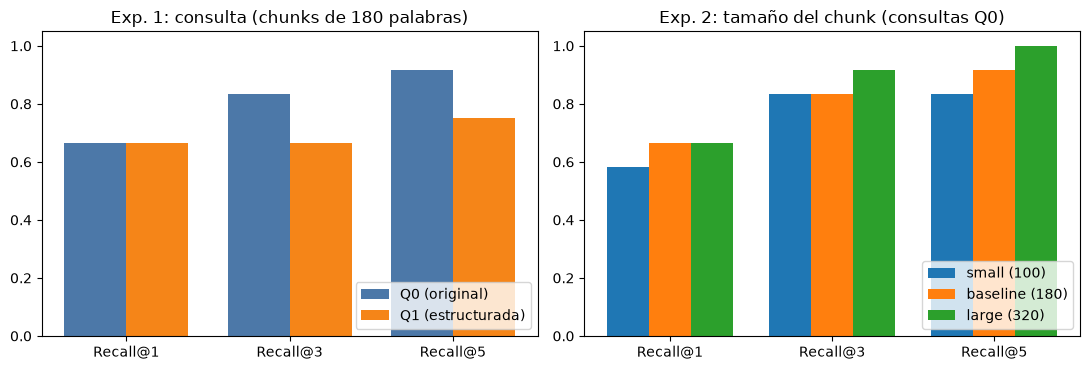

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(len(K_VALUES)); w = 0.38
axes[0].bar(x - w / 2, [exp1_summary[f"mean_recall@{k}_Q0"] for k in K_VALUES], w, label="Q0 (original)", color="#4c78a8")
axes[0].bar(x + w / 2, [exp1_summary[f"mean_recall@{k}_Q1"] for k in K_VALUES], w, label="Q1 (estructurada)", color="#f58518")
axes[0].set_xticks(x); axes[0].set_xticklabels([f"Recall@{k}" for k in K_VALUES]); axes[0].set_ylim(0, 1.05)
axes[0].set_title("Exp. 1: consulta (chunks de 180 palabras)"); axes[0].legend(loc="lower right")
w = 0.26
for i, name in enumerate(["small", "baseline", "large"]):
    vals = [exp2_summary.set_index("condición").loc[name, f"Recall@{k}"] for k in K_VALUES]
    axes[1].bar(x + (i - 1) * w, vals, w, label=f"{name} ({TARGET_WORDS[name]})")
axes[1].set_xticks(x); axes[1].set_xticklabels([f"Recall@{k}" for k in K_VALUES]); axes[1].set_ylim(0, 1.05)
axes[1].set_title("Exp. 2: tamaño del chunk (consultas Q0)"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.savefig(RESULTS / "fig_resumen.png", dpi=150); plt.show()

In [23]:
def sha(text: str) -> str:
    return hashlib.sha256(text.encode("utf-8")).hexdigest()[:12]

# Resultados por experimento
exp1.to_csv(RESULTS / "exp1_consulta.csv", index=False, encoding="utf-8")
structured_df.to_csv(RESULTS / "q1_estructuradas.csv", index=False, encoding="utf-8")
(RESULTS / "q1_estructuradas.jsonl").write_text(
    "\n".join(json.dumps(r, ensure_ascii=False) for r in structured.values()) + "\n", encoding="utf-8")
pivot.reset_index().rename(columns={"index": "query_id"}).to_csv(RESULTS / "exp2_chunking_por_consulta.csv", index=False, encoding="utf-8")
exp2_summary.to_csv(RESULTS / "exp2_chunking.csv", index=False, encoding="utf-8")

top3_rows = []
for name, r in cond_results.items():
    for _, row in r["per_query"].iterrows():
        for t in row["top3"]:
            top3_rows.append({"condicion": name, "query_id": row["query_id"], **t})
pd.DataFrame(top3_rows).to_csv(RESULTS / "exp2_top3.csv", index=False, encoding="utf-8")

(RESULTS / "prompts_renderizados.jsonl").write_text(
    "\n".join(json.dumps(r, ensure_ascii=False) for r in rendered_prompts) + "\n", encoding="utf-8")

resumen = pd.DataFrame([
    {"experimento": "consulta", "condicion": "Q0", "n": len(qids), "schema_valid_rate": None,
     "recall@1": exp1_summary["mean_recall@1_Q0"], "recall@3": exp1_summary["mean_recall@3_Q0"], "recall@5": exp1_summary["mean_recall@5_Q0"]},
    {"experimento": "consulta", "condicion": "Q1", "n": len(qids), "schema_valid_rate": schema_valid_rate,
     "recall@1": exp1_summary["mean_recall@1_Q1"], "recall@3": exp1_summary["mean_recall@3_Q1"], "recall@5": exp1_summary["mean_recall@5_Q1"]},
] + [
    {"experimento": "chunking", "condicion": f"{r['condición']} ({r['target_words']})", "n": len(qids), "schema_valid_rate": None,
     "recall@1": r["Recall@1"], "recall@3": r["Recall@3"], "recall@5": r["Recall@5"]}
    for _, r in exp2_summary.iterrows()
])
resumen.round(4).to_csv(RESULTS / "resumen_experimentos.csv", index=False, encoding="utf-8")

config = {
    "llm_id": LLM_ID, "llm_revision": LLM_REVISION, "encoder_id": ENCODER_ID,
    "embedding_dim": int(ENC_DIM), "encoder_max_seq_length": int(encoder.max_seq_length),
    "torch": torch.__version__, "transformers": transformers.__version__,
    "sentence_transformers": sentence_transformers.__version__, "faiss": faiss.__version__, "jsonschema": importlib.metadata.version("jsonschema"),
    "python": platform.python_version(), "seed": SEED,
    "decoding": {"do_sample": False, "max_new_tokens": MAX_NEW_TOKENS, "repetition_penalty": REPETITION_PENALTY},
    "target_words": TARGET_WORDS, "overlap_passages": OVERLAP_PASSAGES, "k_values": K_VALUES,
    "index": "faiss.IndexFlatIP", "normalizacion": "L2", "prefijos": ["query: ", "passage: "],
    "corpus_sha256": sha((DATA / "corpus_pc2.jsonl").read_text(encoding="utf-8")),
    "queries_sha256": sha((DATA / "queries_pc2.jsonl").read_text(encoding="utf-8")),
    "qrels_sha256": sha((DATA / "qrels_pc2.json").read_text(encoding="utf-8")),
    "prompt_sha256": sha(raw_prompt), "schema": SCHEMA,
    "n_documentos": len(documents), "n_passages": len(all_passages), "n_consultas": len(queries),
    "exp1": exp1_summary,
}
(RESULTS / "config_corrida.json").write_text(json.dumps(config, ensure_ascii=False, indent=2, default=float), encoding="utf-8")
resumen.round(3)

,experimento,condicion,n,schema_valid_rate,recall@1,recall@3,recall@5
0,consulta,Q0,6,NaN,0.667,0.833,0.917
1,consulta,Q1,6,0.833,0.667,0.667,0.750
2,chunking,small (100),6,NaN,0.583,0.833,0.833
3,chunking,baseline (180),6,NaN,0.667,0.833,0.917
4,chunking,large (320),6,NaN,0.667,0.917,1.000


## 14. Limitaciones de este piloto
- **Escala:** 6 consultas, 50 passages, una corrida por condición; una consulta pesa 0.167 en la media. Sin intervalos de confianza: diferencias de una consulta están dentro del ruido.
- **LLM pequeño:** Qwen2.5-0.5B ya mostró en la PC1 que sigue mal las reglas; aquí solo debe reformular, pero su calidad condiciona Q1.
- **Corpus resumido por mí:** los passages son resúmenes en español de fuentes públicas; las cifras provienen de la fuente, pero la redacción (y por tanto el léxico compartido con mis consultas) es mía.
- **Recall sobre passages cubiertos:** un chunk grande cubre más passages, lo que puede inflar Recall@k; por eso se reporta `evidence_precision@3`.
- **Qrels binarios y mínimos:** no marco passages "parcialmente relevantes"; algunas consultas podrían aceptar más evidencia que la anotada.